# AI4I 2020 Predictive Maintenance - Advanced Binary Failure Classification

## 1. Business Problem & Project Overview

This project aims to develop a robust, end-to-end Machine Learning pipeline for binary predictive maintenance classification using industrial machine operating data. In most factory settings, the primary business value lies in anticipating anomalous machine behavior to issue proactive alerts, allowing technicians to diagnose the issue before critical downtime occurs.

**Objective:** Build a scalable, production-ready binary classification system (Failure vs. Normal Operation) using Gradient Boosting architectures. By aggregating all minority failure modes (Tool Wear, Overstrain, Heat Dissipation, etc.) into a single anomaly class, we significantly improve the statistical volume for model learning, and we handle the remaining class imbalance with cost-sensitive learning (balanced sample weights) instead of synthetic oversampling.

**Key Workflow Steps:**
1. Data Acquisition & Initial Cleaning
2. Failure Mode EDA & Data Quality Checks
3. Binary Target Definition (Leakage Prevention)
4. Stratified Train-Validation-Test Split
5. Domain-Specific Feature Engineering & Custom Transformers
6. Preprocessing Pipelines
7. Class Imbalance Handling with Sample Weights
8. Automatic Gradient Boosting Model Benchmarking
9. Dynamic Hyperparameter Optimization using Optuna
10. Final Model Training & Evaluation on the Unseen Test Set
11. Decision Threshold Selection (Out-of-Fold) & Business Trade-off

## 2. Environment Setup & Imports

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (f1_score, recall_score, confusion_matrix, classification_report,
                             precision_recall_curve, average_precision_score, roc_auc_score)

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

## 3. Data Acquisition & Initial Cleaning

In [2]:
# Relative to notebooks/, so the path works in any clone of the repository.
data_path = Path("..") / "data" / "ai4i2020.csv"

def load_and_clean_data(filepath) -> pd.DataFrame:
    df = pd.read_csv(filepath)

    # 'Torque [Nm]' -> 'torque_nm'
    df.columns = df.columns.str.strip().str.lower()
    df.columns = df.columns.str.replace(r"[\[\]]", "", regex=True)
    df.columns = df.columns.str.replace(" ", "_")

    # Row and product identifiers carry no physical signal.
    df = df.drop(columns=['udi', 'product_id'], errors='ignore')

    print(f"Data loaded successfully. Final shape: {df.shape}")
    return df

df_raw = load_and_clean_data(data_path)
display(df_raw.head())

Data loaded successfully. Final shape: (10000, 12)


,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 4. Failure Mode EDA & Data Quality Checks

Before collapsing the failure modes into a binary target, we inspect how the five specific failure flags are distributed and whether they are consistent with the global `machine_failure` label.

Rows with more than one failure mode:            24
Machine failures without any failure mode flag: 9
Failure mode flags without machine failure:     18


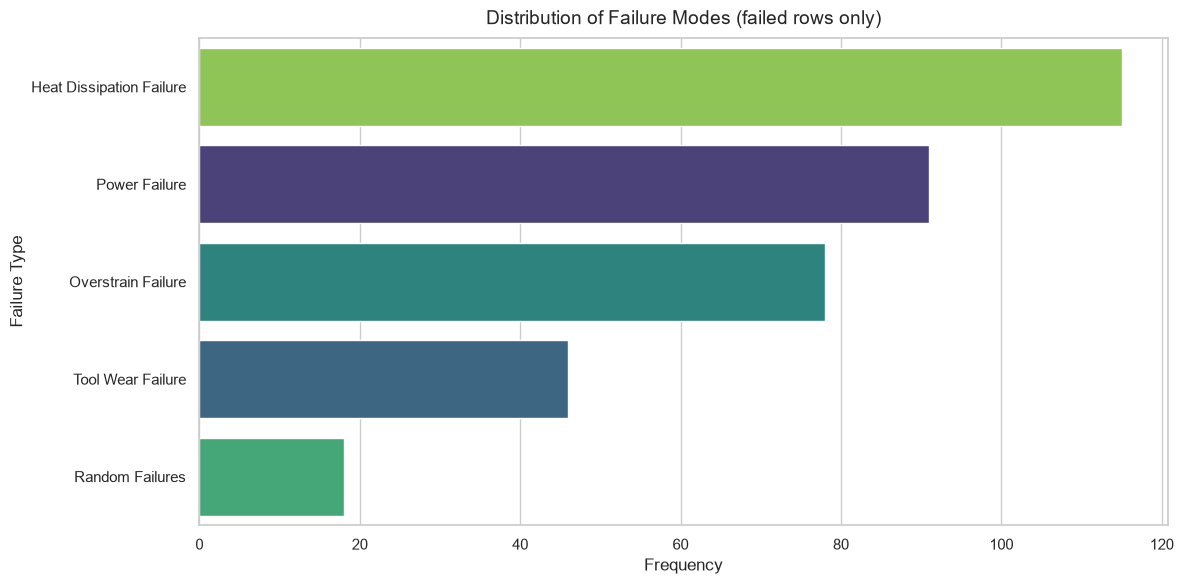

In [3]:
df = df_raw.copy()
failure_flags = ['twf', 'hdf', 'pwf', 'osf', 'rnf']

# Label each row with its failure mode (first matching flag wins when several are active)
conditions = [df[flag] == 1 for flag in failure_flags]
choices = [
    'Tool Wear Failure',
    'Heat Dissipation Failure',
    'Power Failure',
    'Overstrain Failure',
    'Random Failures'
]
df['failure_type'] = np.select(conditions, choices, default='No Failure')

# Data quality: the failure flags and the global label are not perfectly aligned in this dataset
n_modes = df[failure_flags].sum(axis=1)
print(f"Rows with more than one failure mode:            {(n_modes > 1).sum()}")
print(f"Machine failures without any failure mode flag: {((df['machine_failure'] == 1) & (n_modes == 0)).sum()}")
print(f"Failure mode flags without machine failure:     {((df['machine_failure'] == 0) & (n_modes > 0)).sum()}")

# Visualizing the failure mode distribution (excluding the dominant 'No Failure' class)
plt.figure(figsize=(12, 6))
failures_only = df[df['failure_type'] != 'No Failure']
order = failures_only['failure_type'].value_counts().index
sns.countplot(data=failures_only, y='failure_type', hue='failure_type', order=order, palette="viridis", legend=False)
plt.title("Distribution of Failure Modes (failed rows only)", fontsize=14, pad=10)
plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Failure Type", fontsize=12)
plt.tight_layout()
plt.show()

**Takeaways:**
- Individual failure modes have only a few dozen examples each (Random Failures are extremely rare), which confirms that modeling them separately would be statistically unreliable.
- The flags and `machine_failure` do not always agree (some failures have no mode flag, and some Random Failure flags are not labeled as machine failures). This is a known characteristic of the AI4I dataset, and it is another reason to use `machine_failure` as the single source of truth for the target.

## 5. Binary Target Definition (Leakage Prevention)

Binary target column defined: 'machine_failure'
Failure rate: 3.39%


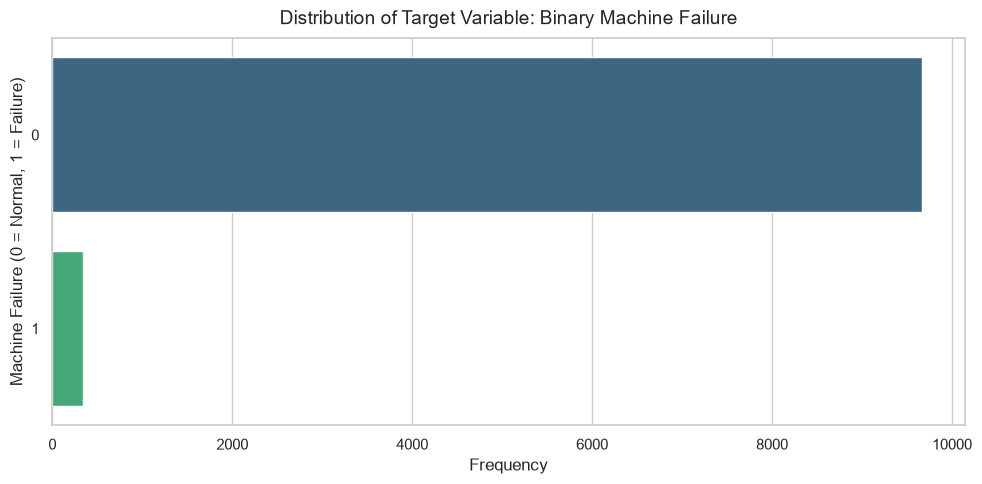

In [4]:
# 'machine_failure' is already binary. The per-mode flags are that same label broken down
# by cause, so keeping them as inputs would be pure leakage.
target_col = 'machine_failure'
leakage_cols = failure_flags + ['failure_type']
df = df.drop(columns=leakage_cols)

print(f"Binary target column defined: '{target_col}'")
print(f"Failure rate: {df[target_col].mean():.2%}")

plt.figure(figsize=(10, 5))
sns.countplot(data=df, y=target_col, hue=target_col, palette="viridis", orient='h', legend=False)
plt.title("Distribution of Target Variable: Binary Machine Failure", fontsize=14, pad=10)
plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Machine Failure (0 = Normal, 1 = Failure)", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Stratified Train-Validation-Test Split

In [5]:
X = df.drop(columns=[target_col])
y = df[target_col].astype(int)

# Stratified 70/15/15 split: with ~3% failures, an unstratified split could leave
# validation or test with too few positives to measure recall.
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15 / 0.85, random_state=RANDOM_STATE, stratify=y_temp)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Failure distribution in train set: Normal={np.bincount(y_train)[0]}, Failure={np.bincount(y_train)[1]}")

Training set shape: (7000, 6)
Validation set shape: (1500, 6)
Testing set shape: (1500, 6)
Failure distribution in train set: Normal=6763, Failure=237


## 7. Feature Engineering & Custom Transformers
Building Custom Scikit-Learn Transformers guarantees that our feature engineering steps are cleanly applied via pipelines, strictly preventing data leakage across our splits.

The engineered features follow the physical failure mechanisms documented for the AI4I 2020 dataset:
- **Heat Dissipation Failure** depends on the difference between process and air temperature (combined with low rotational speed).
- **Power Failure** depends on the mechanical power, `P [W] = Torque [Nm] × ω [rad/s]`, with `ω = rpm × 2π / 60`.
- **Overstrain Failure** depends on the product of tool wear and torque (`[min·Nm]`).

In [6]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Physics-based features, each one mirroring the rule behind a failure mode."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        # HDF: triggered when the process-air difference drops below 8.6 K at low speed.
        if 'process_temperature_k' in X_out.columns and 'air_temperature_k' in X_out.columns:
            X_out['temperature_diff'] = X_out['process_temperature_k'] - X_out['air_temperature_k']

        # PWF: triggered when power (torque x angular velocity) leaves the 3,500-9,000 W band.
        if 'torque_nm' in X_out.columns and 'rotational_speed_rpm' in X_out.columns:
            X_out['power_w'] = X_out['torque_nm'] * X_out['rotational_speed_rpm'] * 2 * np.pi / 60

        # OSF: triggered when tool wear x torque exceeds 11,000-13,000 min*Nm (by product type).
        if 'tool_wear_min' in X_out.columns and 'torque_nm' in X_out.columns:
            X_out['wear_torque_strain'] = X_out['tool_wear_min'] * X_out['torque_nm']
        return X_out

class RareCategoryEncoder(BaseEstimator, TransformerMixin):
    """Map categories rarer than `threshold` (share of training rows) to 'Other'."""

    def __init__(self, threshold=0.05):
        self.threshold = threshold

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.columns_ = X_df.columns
        self.freqs_ = {col: X_df[col].value_counts(normalize=True) for col in self.columns_}
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.columns_)
        for col in self.columns_:
            rare = self.freqs_[col][self.freqs_[col] < self.threshold].index
            X_df[col] = X_df[col].replace(rare, "Other")
        return X_df.values

## 8. Defining Preprocessing Pipelines

**No outlier clipping on purpose:** in this problem, extreme torque, power and strain values are not noise, they are the failure signal itself (almost every observation outside the usual range corresponds to a failure). Clipping them would flatten exactly the information the model needs, so numerical features are only imputed and scaled. Scaling does not change tree-based models, but it keeps the pipeline ready for distance-based or linear baselines.

In [7]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('rare', RareCategoryEncoder(threshold=0.05)),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_exclude=np.number))
], remainder='passthrough'
)

data_pipeline = Pipeline([
    ('feat_eng', FeatureEngineer()),
    ('preprocess', preprocessor)
])

## 9. Preprocessing & Sample Weight Calculation

To handle the class imbalance (~3.4% failures) robustly across all Gradient Boosting frameworks, we pre-process the splits and compute balanced sample weights. This cost-sensitive approach avoids the synthetic noise that oversampling techniques such as SMOTE can introduce on a small minority class.

In [8]:
# Fit on train only; validation and test are transformed with the train statistics.
X_train_processed = data_pipeline.fit_transform(X_train)
X_val_processed = data_pipeline.transform(X_val)
X_test_processed = data_pipeline.transform(X_test)

# Cost-sensitive learning instead of resampling: 'balanced' weights make each failure
# count about 28x a normal row.
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

print("Data transformed successfully.")
print(f"Computed sample weights for {len(sample_weights)} training samples.")
print(f"Weight per class: Normal={sample_weights[y_train.values == 0][0]:.3f}, Failure={sample_weights[y_train.values == 1][0]:.3f}")

Data transformed successfully.
Computed sample weights for 7000 training samples.
Weight per class: Normal=0.518, Failure=14.768


## 10. Model Benchmarking (Automatic)

We benchmark multiple architectures by passing the `sample_weight` array directly into the `.fit()` method. This ensures a standardized, cost-sensitive learning approach across Scikit-Learn, XGBoost, LightGBM, and CatBoost APIs (no model-specific class weights are added, to avoid weighting the minority class twice).

Models are ranked by **Validation Macro F1** (at the default 0.5 threshold). **PR-AUC** (Average Precision) is reported as a threshold-independent complement, which is more informative than ROC-AUC under heavy class imbalance.

Evaluating Gradient Boosting...


Evaluating HistGradientBoosting...


Evaluating XGBoost...


Evaluating LightGBM...
Evaluating CatBoost...


,Model,Validation Macro F1,Validation Failure F1,Validation PR-AUC
0,XGBoost,0.908362,0.822222,0.834781
1,HistGradientBoosting,0.896730,0.800000,0.812582
2,CatBoost,0.890320,0.787879,0.811724
3,LightGBM,0.881629,0.770833,0.814809
4,Gradient Boosting,0.815063,0.646154,0.847790


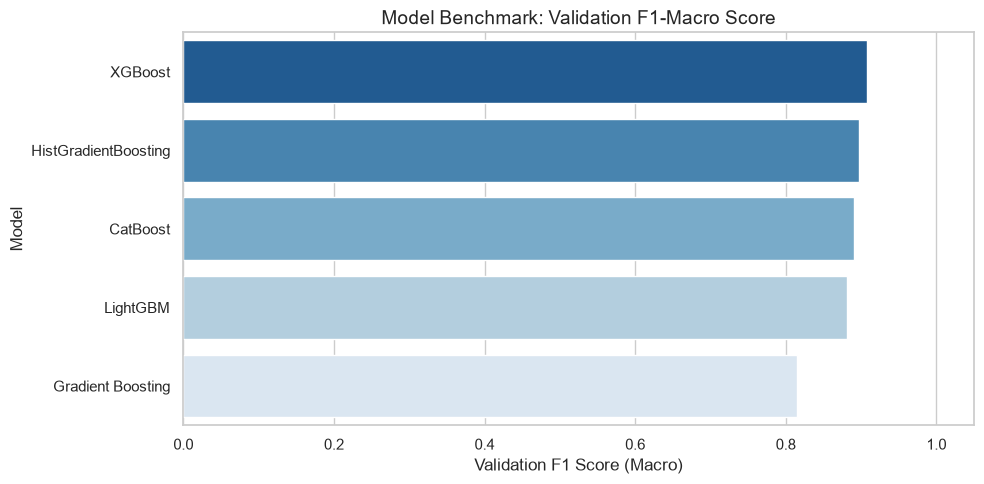

In [9]:
# Imbalance goes through sample_weight in fit, the one mechanism all five libraries share,
# instead of each library's own option (class_weight, scale_pos_weight, ...).
benchmark_models = {
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)
}

bench_results = []

for name, model in benchmark_models.items():
    print(f"Evaluating {name}...")

    model.fit(X_train_processed, y_train, sample_weight=sample_weights)
    y_val_pred = model.predict(X_val_processed)
    y_val_proba = model.predict_proba(X_val_processed)[:, 1]

    bench_results.append({
        'Model': name,
        # Macro F1 gives the same importance to the failure class as to the normal class
        'Validation Macro F1': f1_score(y_val, y_val_pred, average='macro'),
        'Validation Failure F1': f1_score(y_val, y_val_pred),
        'Validation PR-AUC': average_precision_score(y_val, y_val_proba)
    })

df_bench = pd.DataFrame(bench_results).sort_values(by='Validation Macro F1', ascending=False).reset_index(drop=True)
display(df_bench)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_bench, x='Validation Macro F1', y='Model', hue='Model', palette='Blues_r', legend=False)
plt.title("Model Benchmark: Validation F1-Macro Score", fontsize=14)
plt.xlabel("Validation F1 Score (Macro)")
plt.ylabel("Model")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

## 11. Automatic Hyperparameter Tuning (Optuna)
We extract the top-performing model from the benchmark dynamically and tune it. Each trial fits a fresh copy of the full pipeline (preprocessing + classifier) with the **same balanced sample weights used in the benchmark**, so that tuned and baseline scores are directly comparable. The TPE sampler is seeded for reproducibility.

In [10]:
# The benchmark is sorted by validation macro F1, so the first row is the winner.
best_model_name = df_bench.iloc[0]['Model']
baseline_score = df_bench.iloc[0]['Validation Macro F1']
print(f"Best model automatically selected for tuning: {best_model_name} (baseline Macro F1 = {baseline_score:.4f})")

def get_optuna_params(trial, model_name):
    """Optuna search space for each benchmark model."""
    if model_name == 'Gradient Boosting':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 500),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20)
        }

    elif model_name == 'HistGradientBoosting':
        return {
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'max_iter': trial.suggest_int('max_iter', 50, 500),
            'max_depth': trial.suggest_int('max_depth', 3, 12),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 10, 100)
        }

    elif model_name == 'XGBoost':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 500),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 12),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 10.0, log=True)
        }

    elif model_name == 'LightGBM':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 500),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 20, 200),
            'max_depth': trial.suggest_int('max_depth', 3, 12)
        }

    elif model_name == 'CatBoost':
        return {
            'iterations': trial.suggest_int('iterations', 50, 500),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'depth': trial.suggest_int('depth', 4, 10),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0)
        }

    raise ValueError(f"Model {model_name} is not supported.")

def get_model_instance(model_name, dynamic_params):
    """Instantiate `model_name` with its fixed base parameters plus `dynamic_params`."""
    if model_name == 'Gradient Boosting':
        base_params = {'random_state': RANDOM_STATE}
        return GradientBoostingClassifier(**base_params, **dynamic_params)

    elif model_name == 'HistGradientBoosting':
        base_params = {'random_state': RANDOM_STATE}
        return HistGradientBoostingClassifier(**base_params, **dynamic_params)

    elif model_name == 'XGBoost':
        base_params = {'random_state': RANDOM_STATE, 'eval_metric': 'logloss'}
        return XGBClassifier(**base_params, **dynamic_params)

    elif model_name == 'LightGBM':
        base_params = {'random_state': RANDOM_STATE, 'verbose': -1}
        return LGBMClassifier(**base_params, **dynamic_params)

    elif model_name == 'CatBoost':
        base_params = {'random_state': RANDOM_STATE, 'verbose': 0, 'allow_writing_files': False}
        return CatBoostClassifier(**base_params, **dynamic_params)

    raise ValueError(f"Model {model_name} is not supported.")

def build_pipeline(model_name, params):
    """Unfitted preprocessing + classifier pipeline (the preprocessor is cloned, never shared)."""
    return Pipeline([
        ('data_prep', clone(data_pipeline)),
        ('classifier', get_model_instance(model_name, params))
    ])

def objective(trial, model_name, X_train_split, y_train_split, X_val_split, y_val_split):
    """Validation macro F1 of one trial; the test set never takes part in tuning."""
    params = get_optuna_params(trial, model_name)
    full_pipeline = build_pipeline(model_name, params)

    # Same cost-sensitive setup as the benchmark: balanced weights routed to the classifier step
    weights = compute_sample_weight(class_weight='balanced', y=y_train_split)
    full_pipeline.fit(X_train_split, y_train_split, classifier__sample_weight=weights)

    y_val_pred = full_pipeline.predict(X_val_split)
    return f1_score(y_val_split, y_val_pred, average='macro')

N_TRIALS = 40
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))

print(f"Starting Optuna Tuning for {best_model_name} ({N_TRIALS} trials)...")
study.optimize(lambda trial: objective(trial, best_model_name, X_train, y_train, X_val, y_val),
               n_trials=N_TRIALS, show_progress_bar=False)

print("Optimization Completed.")
print(f"Best Validation Macro F1: {study.best_value:.4f} (baseline: {baseline_score:.4f})")
print(f"Best Parameters: {study.best_params}")

# Only keep the tuned parameters if they actually beat the default configuration on validation
best_params = study.best_params if study.best_value > baseline_score else {}
print("Using tuned parameters." if best_params else "Tuning did not beat the defaults; keeping default parameters.")

Best model automatically selected for tuning: XGBoost (baseline Macro F1 = 0.9084)
Starting Optuna Tuning for XGBoost (40 trials)...


Optimization Completed.
Best Validation Macro F1: 0.8991 (baseline: 0.9084)
Best Parameters: {'n_estimators': 497, 'learning_rate': 0.11448705664680427, 'max_depth': 6, 'subsample': 0.7020261691519469, 'colsample_bytree': 0.9506404929898924, 'min_child_weight': 1.3145949501196494}
Tuning did not beat the defaults; keeping default parameters.


## 12. Final Model Evaluation on the Unseen Test Set
The final pipeline is retrained on the combined training and validation sets (with sample weights recomputed on the combined data) and evaluated once on the untouched test set.

In [11]:
final_pipeline = build_pipeline(best_model_name, best_params)

# Hyperparameters are frozen, so refit on train + validation before the one-off test run.
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])
sample_weights_full = compute_sample_weight(class_weight='balanced', y=y_train_full)
final_pipeline.fit(X_train_full, y_train_full, classifier__sample_weight=sample_weights_full)

y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]

target_names = ['Normal (0)', 'Failure (1)']
print("Classification Report (Final Test Set, threshold = 0.50):\n")
print(classification_report(y_test, y_test_pred, target_names=target_names))
print(f"Test Macro F1: {f1_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Test PR-AUC:   {average_precision_score(y_test, y_test_proba):.4f}")
# ROC-AUC is reported for completeness: with a 3.4% failure rate it looks better than
# PR-AUC because the false-positive rate is computed over ~1,450 normal machines.
print(f"Test ROC-AUC:  {roc_auc_score(y_test, y_test_proba):.4f}")

Classification Report (Final Test Set, threshold = 0.50):

              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00      1449
 Failure (1)       0.90      0.90      0.90        51

    accuracy                           0.99      1500
   macro avg       0.95      0.95      0.95      1500
weighted avg       0.99      0.99      0.99      1500

Test Macro F1: 0.9493
Test PR-AUC:   0.9370
Test ROC-AUC:  0.9880


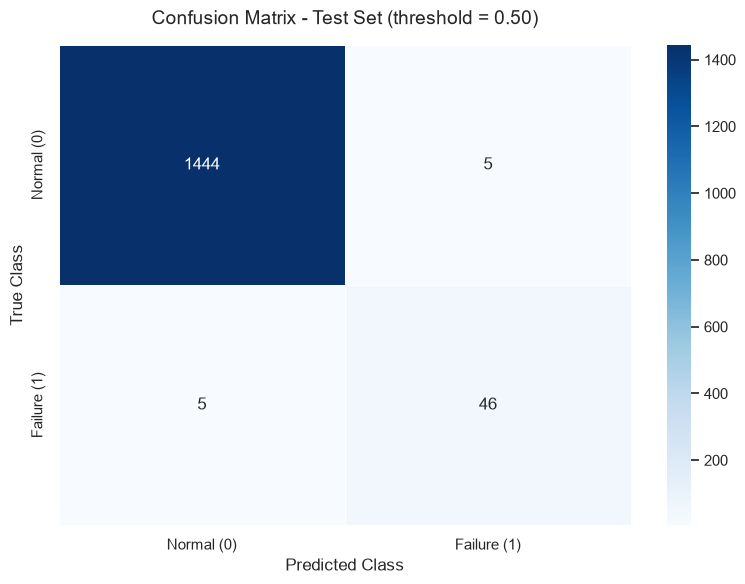

In [12]:
def plot_confusion_matrix_heatmap(y_true, y_pred, class_names, title='Confusion Matrix - Unseen Test Set'):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, linewidths=0.5)

    plt.xlabel('Predicted Class', fontsize=12)
    plt.ylabel('True Class', fontsize=12)
    plt.title(title, fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

plot_confusion_matrix_heatmap(y_test, y_test_pred, target_names, title='Confusion Matrix - Test Set (threshold = 0.50)')

### Error analysis: which failures does the model miss?

The aggregate metrics say *how many* failures are missed; this looks at *which* ones. The failure-mode flags were removed from the features to prevent leakage, but they are still available in `df_raw` to explain the errors after the fact.

In [13]:
# Join the test predictions (default 0.50 threshold) back to the raw columns that explain them.
# The failure-mode flags are used here only to read the errors, never as model inputs.
error_view = df_raw.loc[X_test.index, ['type', 'tool_wear_min', 'torque_nm', 'rotational_speed_rpm'] + failure_flags].copy()
error_view['y_true'] = y_test.to_numpy()
error_view['y_pred'] = y_test_pred
error_view['failure_proba'] = y_test_proba.round(3)

missed = error_view[(error_view['y_true'] == 1) & (error_view['y_pred'] == 0)]
false_alarms = error_view[(error_view['y_true'] == 0) & (error_view['y_pred'] == 1)]

print(f"Missed failures (FN): {len(missed)}")
display(missed)
print(f"False alarms (FP): {len(false_alarms)}")
display(false_alarms)

# Recall per failure mode on the test set (a failure can carry more than one flag)
per_mode = pd.DataFrame({
    flag.upper(): {
        'failures in test': int(error_view[flag].eq(1).sum()),
        'caught': int((error_view[flag].eq(1) & error_view['y_pred'].eq(1)).sum()),
    }
    for flag in failure_flags
}).T
per_mode['recall'] = (per_mode['caught'] / per_mode['failures in test']).round(2)
display(per_mode)


Missed failures (FN): 5


,type,tool_wear_min,torque_nm,rotational_speed_rpm,twf,hdf,pwf,osf,rnf,y_true,y_pred,failure_proba
1996,M,198,38.2,1416,1,0,0,0,0,1,0,0.000
4034,L,235,29.0,1615,1,0,0,0,0,1,0,0.012
3695,L,207,37.3,1530,1,0,0,0,0,1,0,0.104
7087,L,217,30.5,1648,1,0,0,0,0,1,0,0.026
8506,L,163,27.3,1710,0,0,0,0,0,1,0,0.002


False alarms (FP): 5


,type,tool_wear_min,torque_nm,rotational_speed_rpm,twf,hdf,pwf,osf,rnf,y_true,y_pred,failure_proba
330,M,215,41.9,1398,0,0,0,0,0,0,1,0.670
5307,L,211,34.8,1530,0,0,0,0,0,0,1,0.662
5391,L,228,34.4,1572,0,0,0,0,0,0,1,0.516
3026,M,221,21.9,1888,0,0,0,0,0,0,1,0.678
5988,H,204,58.2,1296,0,0,0,0,0,0,1,0.955


,failures in test,caught,recall
TWF,5,1,0.2
HDF,21,21,1.0
PWF,11,11,1.0
OSF,15,15,1.0
RNF,1,0,0.0


**Reading the errors:**

- **4 of the 5 missed failures are Tool Wear Failures (TWF)**, with tools at 198 to 235 minutes of use, and the model catches only 1 of the 5 TWF in the test set. In this dataset a tool fails at a random point between roughly 200 and 240 minutes of wear, so a machine at, say, 210 minutes looks the same whether its tool is about to fail or not.
- The fifth miss is labelled `machine_failure = 1` with no failure-mode flag at all: one of the label inconsistencies found in section 4. There is no physical signal to learn from it.
- **All 5 false alarms are machines in that same wear window (204 to 228 minutes).** The model has learned that this window is risky, which is correct, but it cannot tell which tools will actually fail.
- Every heat dissipation, power and overstrain failure in the test set is caught (21, 11 and 15 of them): their physics is captured by the engineered features (`temperature_diff`, `power_w`, `wear_torque_strain`).

The remaining error is concentrated where the data itself is ambiguous, so more tuning would not remove it; a feature that measures tool condition directly (vibration, acoustic emission) would.

## 13. Decision Threshold Selection (Out-of-Fold)

The decision threshold is a business lever, but it must **not** be chosen by looking at the test set, otherwise the reported test metrics become optimistically biased. Instead, we generate **out-of-fold (OOF) probabilities** on the combined train+validation data with 5-fold stratified cross-validation (same pipeline, same sample weights) and pick the thresholds there. The test set is only used afterwards to confirm each strategy.

Three operating points are compared:
- **A - Default (0.50)**: the model output as-is (already recall-oriented, because of the balanced sample weights).
- **B - F1-optimal**: the threshold that maximizes the failure-class F1 out-of-fold.
- **C - Risk-averse**: the highest threshold that still reaches 90% recall out-of-fold.

OOF at default threshold 0.50 -> recall: 0.781
B | F1-optimal threshold: 0.868 -> OOF precision: 0.986 | OOF recall: 0.760
C | Recall >= 90% threshold: 0.007 -> OOF precision: 0.334 | OOF recall: 0.903


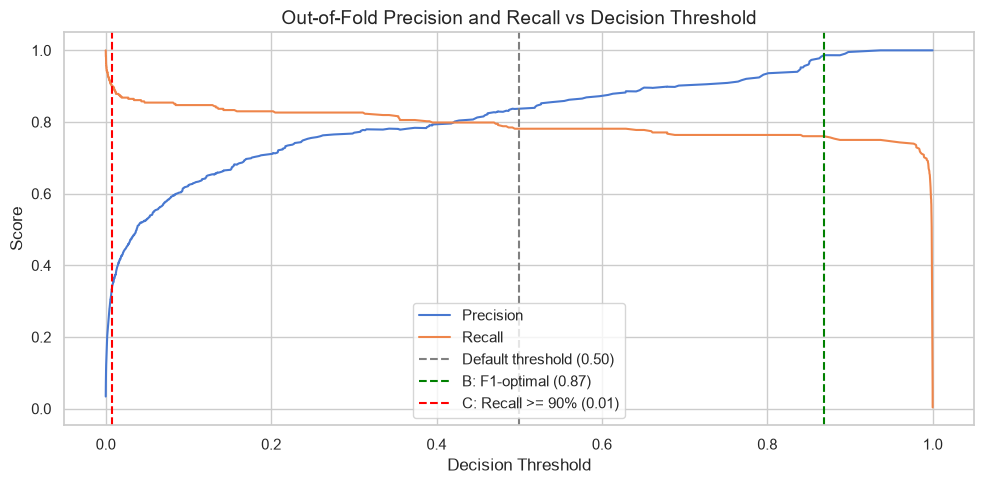

In [14]:
# Out-of-fold probabilities: each sample is predicted by a model that did not see it during training
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(
    build_pipeline(best_model_name, best_params), X_train_full, y_train_full,
    cv=cv, method='predict_proba', params={'classifier__sample_weight': sample_weights_full}
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train_full, oof_proba)
precision, recall = precision[:-1], recall[:-1]  # align with thresholds

# Strategy B (balanced): the threshold that maximizes the failure-class F1 on OOF data
f1_curve = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
f1_idx = int(np.argmax(f1_curve))
f1_threshold = float(thresholds[f1_idx])

# Strategy C (risk-averse): the highest threshold (i.e. fewest false alarms) that still catches >= 90% of failures OOF
TARGET_RECALL = 0.90
recall_idx = int(np.where(recall >= TARGET_RECALL)[0][-1])
recall_threshold = float(thresholds[recall_idx])

print(f"OOF at default threshold 0.50 -> recall: {recall_score(y_train_full, oof_proba >= 0.5):.3f}")
print(f"B | F1-optimal threshold: {f1_threshold:.3f} -> OOF precision: {precision[f1_idx]:.3f} | OOF recall: {recall[f1_idx]:.3f}")
print(f"C | Recall >= {TARGET_RECALL:.0%} threshold: {recall_threshold:.3f} -> OOF precision: {precision[recall_idx]:.3f} | OOF recall: {recall[recall_idx]:.3f}")

plt.figure(figsize=(10, 5))
plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.axvline(0.5, color='grey', linestyle='--', label='Default threshold (0.50)')
plt.axvline(f1_threshold, color='green', linestyle='--', label=f'B: F1-optimal ({f1_threshold:.2f})')
plt.axvline(recall_threshold, color='red', linestyle='--', label=f'C: Recall >= 90% ({recall_threshold:.2f})')
plt.title('Out-of-Fold Precision and Recall vs Decision Threshold', fontsize=14)
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Apply the OOF-selected thresholds to the unseen test set
def summarize(y_true, y_pred, label):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {'Strategy': label, 'Failures caught (TP)': tp, 'Failures missed (FN)': fn, 'False alarms (FP)': fp,
            'Precision': tp / (tp + fp), 'Recall': tp / (tp + fn), 'Failure F1': f1_score(y_true, y_pred)}

strategies = {
    'A: Default (0.50)': 0.5,
    f'B: F1-optimal OOF ({f1_threshold:.3f})': f1_threshold,
    f'C: Recall >= 90% OOF ({recall_threshold:.3f})': recall_threshold
}
display(pd.DataFrame([
    summarize(y_test, (y_test_proba >= thr).astype(int), label) for label, thr in strategies.items()
]).round(3))

,Strategy,Failures caught (TP),Failures missed (FN),False alarms (FP),Precision,Recall,Failure F1
0,A: Default (0.50),46,5,5,0.902,0.902,0.902
1,B: F1-optimal OOF (0.868),46,5,1,0.979,0.902,0.939
2,C: Recall >= 90% OOF (0.007),49,2,90,0.353,0.961,0.516


## Decision Making: Precision vs. Recall Trade-off

In real-world Predictive Maintenance, the default decision threshold (`0.50`) is rarely the definitive answer. The optimal threshold depends entirely on the company's financial structure: **What is more expensive? A false alarm, or a missed catastrophic failure?**

Because the thresholds were selected on out-of-fold data (not on the test set), the test results below are an honest estimate of how each strategy behaves on unseen machines. Note that the test set contains only 51 failures, so each missed or caught failure moves recall by ~2 percentage points, and that out-of-fold recall at the default threshold was 0.78: the 0.90 observed on this test set is a favorable draw, not a guaranteed level.

### Option A: Default Threshold (0.50) - The "Balanced Alert" Strategy

**Test results:** 46 failures caught, 5 missed, 5 false alarms (Precision = 0.90, Recall = 0.90).

Thanks to the balanced sample weights, the default threshold is already recall-oriented. It is a reasonable general-purpose starting point: 9 out of 10 failures are detected, and 9 out of 10 alerts are real.

### Option B: F1-Optimal Threshold (~0.87) - The "High Precision" Strategy

**Test results:** 46 failures caught, 5 missed, 1 false alarm (Precision = 0.98, Recall = 0.90).

This is the conservative approach, ideal for factories where sending a technician to inspect a machine is expensive or disruptive. On this test set it catches the same failures as Option A with almost no alarm fatigue. Out-of-fold, however, this threshold traded some recall for precision (OOF recall ≈ 0.76 vs 0.78 at 0.50), so in production it should be expected to miss slightly more failures than Option A.

### Option C: Recall ≥ 90% Threshold (~0.007) - The "Risk-Averse" Strategy (Max Recall)

**Test results:** 49 failures caught, 2 missed, 90 false alarms (Precision = 0.35, Recall = 0.96).

To guarantee 90% recall out-of-fold, the threshold has to drop to almost zero: the model catches nearly every failure, but roughly two out of three alerts are false alarms. This only makes sense for critical infrastructure where a single unexpected breakdown stops the entire production line and inspections are cheap.

### Conclusion

The model adapts to any of these scenarios **without retraining**: only the decision threshold changes. With a PR-AUC of ~0.94 on the unseen test set, the ranking of risky machines is strong. The remaining misses are concentrated in Tool Wear Failures (4 of the 5 at the default threshold, see the error analysis above), which in this dataset occur at a random point between roughly 200 and 240 minutes of tool use, so no threshold can fully separate them from healthy tools with similar wear. The final choice between **Option A**, **B** and **C** is strategic and should be made together with managers and stakeholders, ideally by assigning an explicit cost to false alarms and to missed failures.